# BT4012 Kaggle Competition Notebook
*By: Dominic Bryan (e1136829)*

In [1]:
# Utilities
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import optuna

# Classifiers
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import lightgbm
from lightgbm import LGBMClassifier

# Evaluation
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, precision_score, accuracy_score, recall_score, classification_report

## File Directories

Please change this directory according to the location of the training, testing, and edgelist data respectively.

In [2]:
TRAIN_DIRECTORY = "./data/train.csv" # Training data directory
TEST_DIRECTORY = "./data/test.csv" # Testing data directory
EDGELIST_DIRECTORY = "./data/txs_edgelist.csv" # Edgelist data directory

## Introduction

### Data Set Features

In [3]:
df_train = pd.read_csv(TRAIN_DIRECTORY)
df_test = pd.read_csv(TEST_DIRECTORY)
feature_cols = df_train.columns[df_train.columns.str.startswith('feat_')]

display(df_train.head())
print(f"Train data shape: {df_train.shape}")
display(df_test.head())
print(f"Test data shape: {df_test.shape}")
print(f"Number of feature columns: {len(feature_cols)}")

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


Train data shape: (141772, 168)


,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,...,-0.524789,-0.531617,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,2,198827545,36,-0.172282,0.837998,1.018602,0.553368,-0.043875,0.641758,-0.061584,...,1.149152,1.070472,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
3,3,200997190,36,-0.172926,0.156148,1.573595,-0.046932,-0.043875,-0.029140,-0.061584,...,0.125358,0.080204,1.461330,1.461369,0.018279,-0.049041,-0.038193,-0.011377,-1.760926,-1.760984
4,4,200996856,36,-0.171396,1.311640,1.573595,0.478330,-0.004174,0.474034,-0.061584,...,-0.106650,-0.137402,0.258822,0.729391,0.018279,0.393121,0.680158,0.462432,0.359796,1.091185


Test data shape: (15329, 168)
Number of feature columns: 165


In [4]:
print(f"Number of unique `txId` in training data: {df_train['txId'].unique().size}")
print(f"Number of unique `txId` in testing data: {df_test['txId'].unique().size}")

Number of unique `txId` in training data: 141772
Number of unique `txId` in testing data: 15329


In [5]:
df_train['label'].value_counts(dropna=False)

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

In [6]:
from scipy.stats import skew
skews = []
for col in feature_cols:
    skews.append(float(skew(df_train[col])))
skews = pd.Series(skews)
print(f"Number of skewed features: {skews[skews.abs() > 3].size}")

Number of skewed features: 92


In [7]:
outlier_count = 0
for col in feature_cols:
    values = df_train[col]
    q1, q3 = np.percentile(values, 25), np.percentile(values, 75)
    iqr = q3 - q1
    outliers = values[(values < q1 - 3 * iqr) | (values > q3 + 3 * iqr)]
    outlier_count += (outliers.size > 0)
print(f"Number of features with outliers: {outlier_count}")

Number of features with outliers: 135


## Methodology

### Data Preprocessing and Feature Engineering

In [8]:
labeled = df_train[~df_train['label'].isna()]
labeled.head()

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
9,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,-0.613614,0.241128,0.241406,0.604120,0.008632,-0.131155,0.333211,-0.120613,-0.119792,0.0
10,232344069,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,...,-0.613614,0.241128,0.241406,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0.0
11,27553029,1,-0.151357,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.141519,...,-0.582077,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0.0
16,3881097,1,-0.172306,-0.184668,-1.201369,0.028105,-0.043875,-0.029140,0.242712,-0.163640,...,-0.600999,0.241128,0.241406,0.018279,-0.068266,-0.084674,-0.054450,-1.760926,-1.760984,0.0


#### Graph Features

In [9]:
edges = pd.read_csv(EDGELIST_DIRECTORY)
display(edges.head())
print(f"Number of all edges: {edges.shape[0]:,}")

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


Number of all edges: 234,355


In [10]:
graph = nx.DiGraph()
graph.add_edges_from(list(map(tuple, edges.to_numpy())))

# Creating graph metrics
pagerank = nx.pagerank(graph)
degree_centrality = nx.degree_centrality(graph)
closeness_centrality = nx.closeness_centrality(graph)
eg_centrality = nx.eigenvector_centrality(graph)
clustering = nx.clustering(graph)

In [11]:
# Combine graph features with the original data frame by entry
def create_graph_features(df):
    graph_features = df.copy()
    graph_features['in_degree'] = graph_features['txId'].apply(lambda x: graph.in_degree(x))
    graph_features['out_degree'] = graph_features['txId'].apply(lambda x: graph.out_degree(x))
    graph_features['degree_centrality'] = graph_features['txId'].apply(lambda x: degree_centrality[x])
    graph_features['closeness_centrality'] = graph_features['txId'].apply(lambda x: closeness_centrality[x])
    graph_features['ev_centrality'] = graph_features['txId'].apply(lambda x: eg_centrality[x])
    graph_features['clustering'] = graph_features['txId'].apply(lambda x: clustering[x])
    graph_features['pagerank'] = graph_features['txId'].apply(lambda x: pagerank[x])
    return graph_features

engineered_train = create_graph_features(df_train)
engineered_test = create_graph_features(df_test)
display(engineered_train.head())
display(engineered_test.head())

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_164,feat_165,label,in_degree,out_degree,degree_centrality,closeness_centrality,ev_centrality,clustering,pagerank
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.120613,-0.119792,NaN,1,1,0.000010,0.000009,7.284578e-18,0.000000,0.000005
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,-0.120613,-0.119792,NaN,1,1,0.000010,0.000009,2.248997e-17,0.000000,0.000006
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,-0.120613,-0.119792,NaN,1,2,0.000015,0.000007,1.175815e-20,0.000000,0.000007
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.120613,-0.119792,0.0,160,1,0.000790,0.000887,2.693585e-15,0.000311,0.000351
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,0.178136,0.179117,NaN,2,8,0.000049,0.000011,1.409627e-20,0.133333,0.000002


,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_163,feat_164,feat_165,in_degree,out_degree,degree_centrality,closeness_centrality,ev_centrality,clustering,pagerank
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,...,-0.140597,-1.760926,-1.760984,1,2,0.000015,0.000005,8.053529e-23,0.0,0.000003
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,...,-0.097524,-0.120613,-0.119792,4,1,0.000025,0.000029,6.202828e-19,0.0,0.000013
2,2,198827545,36,-0.172282,0.837998,1.018602,0.553368,-0.043875,0.641758,-0.061584,...,-0.140597,-1.760926,-1.760984,6,1,0.000034,0.000041,9.510958e-21,0.0,0.000013
3,3,200997190,36,-0.172926,0.156148,1.573595,-0.046932,-0.043875,-0.029140,-0.061584,...,-0.011377,-1.760926,-1.760984,2,1,0.000015,0.000025,2.312885e-17,0.0,0.000004
4,4,200996856,36,-0.171396,1.311640,1.573595,0.478330,-0.004174,0.474034,-0.061584,...,0.462432,0.359796,1.091185,9,0,0.000044,0.000058,6.477607e-17,0.0,0.000016


## Model Exploration and Final Strategy

In [12]:
labeled_engineered = engineered_train.dropna(subset=['label'])
X = labeled_engineered.drop(columns=['txId', 'label'])
y = labeled_engineered['label']
display(X.head())
display(y.head())

,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_163,feat_164,feat_165,in_degree,out_degree,degree_centrality,closeness_centrality,ev_centrality,clustering,pagerank
3,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,-0.115831,...,0.677799,-0.120613,-0.119792,160,1,0.000790,0.000887,2.693585e-15,0.000311,0.000351
9,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,-0.144554,...,0.333211,-0.120613,-0.119792,59,1,0.000294,0.000275,1.399332e-16,0.000565,0.000085
10,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,-0.144108,...,-0.097524,-0.120613,-0.119792,0,2,0.000010,0.000000,2.597913e-24,0.000000,0.000002
11,1,-0.151357,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.141519,-0.147643,...,-0.097524,-0.120613,-0.119792,1,1,0.000010,0.000005,8.053529e-23,0.000000,0.000003
16,1,-0.172306,-0.184668,-1.201369,0.028105,-0.043875,-0.029140,0.242712,-0.163640,-0.169115,...,-0.054450,-1.760926,-1.760984,1,1,0.000010,0.000007,1.210627e-21,0.000000,0.000002


3     0.0
9     0.0
10    0.0
11    0.0
16    0.0
Name: label, dtype: float64

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter = 200),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Multi-Layer Perceptron": MLPClassifier(random_state=42),
    "Adaptive Boosting": AdaBoostClassifier(random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose = -1),
}

results = {}
for name, model in models.items():
    kfold = StratifiedKFold()
    total_auc = 0
    for train_idx, val_idx in kfold.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        scaler = StandardScaler()
        scaled_X_train = scaler.fit_transform(X_train)
        scaled_X_val = scaler.transform(X_val)
        model.fit(scaled_X_train, y_train)
        y_pred = model.predict_proba(scaled_X_val)[:,1]
        total_auc += roc_auc_score(y_val, y_pred)
    results[name] = total_auc/kfold.get_n_splits()
results = pd.Series(results, name = "avg_val_roc_auc").sort_values(ascending=False)

os.makedirs("./experiment_results", exist_ok = True)
results.to_csv("./experiment_results/model_exploration.csv")
results

LightGBM                  0.983505
Multi-Layer Perceptron    0.981045
Random Forest             0.976888
Adaptive Boosting         0.973353
Logistic Regression       0.960017
K-Nearest Neighbors       0.946474
Decision Tree             0.686383
Name: avg_val_roc_auc, dtype: float64

Thus, LightGBM is chosen to be optimised since it has the highest average validation ROC-AUC.

## Model Development and Validation

In [14]:
# Optuna Objective
def objective(trial:optuna.Trial):

    # Model hyperparameters
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 8, 64, step = 4),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 0.4, log = True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 2500, step = 25),
        "subsample": trial.suggest_float("subsample", 0.4, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True)    
    }

    # Candidate model
    lgbm = LGBMClassifier(
        **params, 
        objective="binary",
        random_state=42,
        verbose = -1,
        is_unbalanced=True,
        subsample_freq=1
    )

    # Fitting through Stratified K-Fold cross-validation
    kfold = StratifiedKFold()
    total_auc = 0
    for train_index, val_index in kfold.split(X, y):
        X_train, y_train = X.iloc[train_index], y.iloc[train_index]    
        X_val, y_val = X.iloc[val_index], y.iloc[val_index]
        lgbm.fit(
            X_train, y_train,
            eval_X=X_val, eval_y=y_val,
            eval_metric="auc",
            callbacks=[lightgbm.early_stopping(100, verbose=False)],
        )
        y_pred = lgbm.predict_proba(X_val)[:,1]
        total_auc += roc_auc_score(y_val, y_pred)

    return total_auc/kfold.get_n_splits() # Average ROC-AUC

STUDY_NAME = "model_development"
lgbm_study = optuna.create_study(
    study_name=STUDY_NAME, 
    direction="maximize",
    storage=f"sqlite:///./experiment_results/{STUDY_NAME}.db", # For reproducibility
    load_if_exists=True,
    sampler = optuna.samplers.TPESampler(seed=42)
)

N_TRIALS = 20
if len(lgbm_study.get_trials()) < N_TRIALS:
    lgbm_study.optimize(objective, n_trials = N_TRIALS - len(lgbm_study.get_trials()))
print(f"Best average validation ROC-AUC value: {lgbm_study.best_value}")
print(f"Best Hyperparameters:\n{"".join([f"  - {k}: {np.round(v, 5)}\n" for k, v in lgbm_study.best_params.items()])}")

[I 2026-10-25 21:56:39,674] Using an existing study with `study_name='model_development'` instead of creating a new one.


Best average validation ROC-AUC value: 0.9813520591027591
Best Hyperparameters:
  - num_leaves: 28
  - max_depth: 10
  - learning_rate: 0.1867
  - n_estimators: 1475
  - subsample: 0.7227
  - colsample_bytree: 0.51978
  - reg_alpha: 0.09476
  - reg_lambda: 1.94354



### Hyperparameter Findings

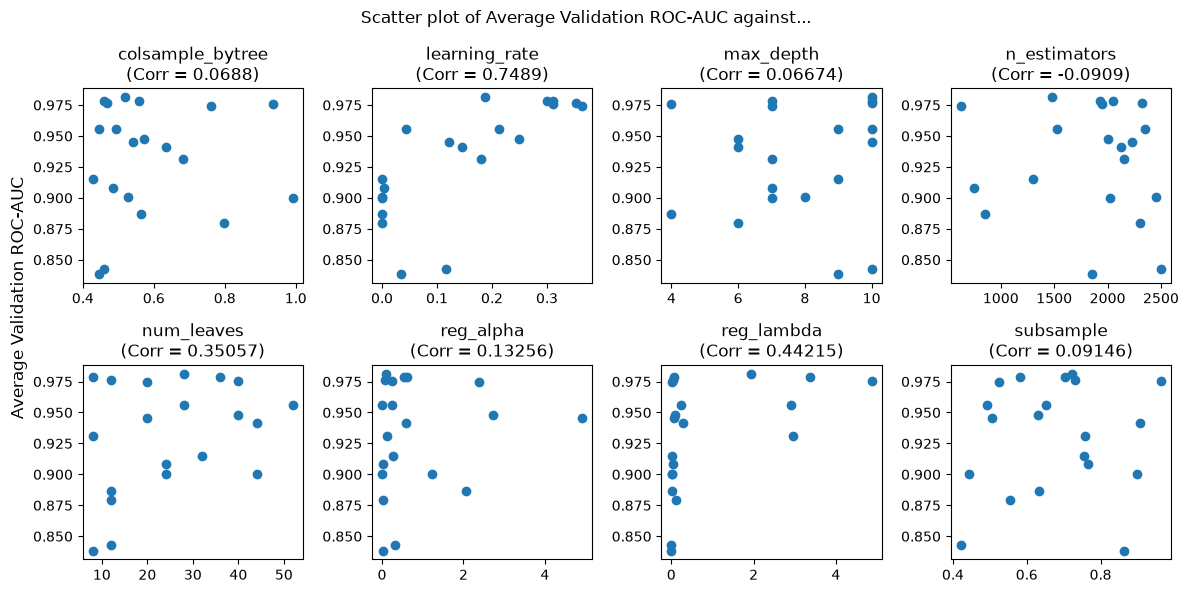

In [15]:
trials_df = lgbm_study.trials_dataframe()
hyperparameters = trials_df.columns[trials_df.columns.str.startswith('params_')]
fig, ax = plt.subplots(nrows=2, ncols=4, figsize = (12,6))
for idx, hp in enumerate(hyperparameters):
    ax[idx//4][idx%4].scatter(
        x = trials_df[hp], 
        y = trials_df['value'],
    )
    ax[idx//4][idx%4].set(
        title = f"{hp.removeprefix('params_')}\n(Corr = {np.round(trials_df[hp].corr(trials_df['value']), 5)})"
    )
fig.supylabel("Average Validation ROC-AUC")
fig.suptitle("Scatter plot of Average Validation ROC-AUC against...")
plt.tight_layout()

## Best Submission Model

The best submission model hyperparameter comes from the best hyper-parameter results of `lgbm_study`:
| `num_leaves` | `max_depth` | `learning_rate` | `n_estimators` | `subsample` | `colsample_bytree` | `reg_alpha` | `reg_lambda` | 
| ---------- | --------- | ------------- | ------------ | --------- | ---------------- | --------- | ---------- | 
| 28         | 10        | 0.1867        | 1,475        | 0.7227    | 0.51878          | 0.09476   | 1.94354    | 


In [16]:
best_params = lgbm_study.best_params

# In case ther are any discrepancies, these were the 
# paramters found to be the best during hyperparameter tuning
#
# best_params = {
#     'num_leaves': 28,
#     'max_depth': 10,
#     'learning_rate': 0.18670277998438123,
#     'n_estimators': 1475,
#     'subsample': 0.7227009256351113,
#     'colsample_bytree': 0.5197766267292666,
#     'reg_alpha': 0.09476117744988771,
#     'reg_lambda': 1.9435415083091632
# }

In [17]:
best_lgbm = lgbm = LGBMClassifier(
    **best_params,
    objective="binary",
    random_state=42,
    verbose = -1,
    is_unbalanced=True,
    subsample_freq=1,
)
best_lgbm.fit(X, y)

,num_leaves,28
,max_depth,10
,learning_rate,0.18670277998438123
,n_estimators,1475
,objective,'binary'
,subsample,0.7227009256351113
,subsample_freq,1
,colsample_bytree,0.5197766267292666
,reg_alpha,0.09476117744988771
,reg_lambda,1.9435415083091632
,random_state,42


### Accuracy Metrics

In [18]:
y_pred = pd.Series(best_lgbm.predict_proba(X)[:,1])
y_pred.head()
print(f"Overall ROC-AUC: {roc_auc_score(y, y_pred)}")
print(f"Overall Classification Report: \n {classification_report(y, y_pred > 0.5)}")

Overall ROC-AUC: 1.0
Overall Classification Report: 
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     27591
         1.0       1.00      1.00      1.00      3644

    accuracy                           1.00     31235
   macro avg       1.00      1.00      1.00     31235
weighted avg       1.00      1.00      1.00     31235



In [19]:
kfold = StratifiedKFold()
metrics = []
for idx, (train_index, val_index) in enumerate(kfold.split(X, y)):
    X_train, y_train = X.iloc[train_index], y.iloc[train_index]    
    X_test, y_test = X.iloc[val_index], y.iloc[val_index]
    best_lgbm.fit(
        X_train, y_train,
        eval_X=X_test, eval_y=y_test,
        eval_metric="auc",
        callbacks=[lightgbm.early_stopping(100, verbose=False)],
    )
    fold_y_pred = best_lgbm.predict_proba(X_test)[:,1]
    print(f" FOLD {idx + 1} METRICS ".center(50, "="))
    print(f"Train Size = {X_train.shape[0]}; Validation Size = {X_test.shape[0]}")
    metric = pd.DataFrame({
        "roc_auc": [roc_auc_score(y_test, fold_y_pred)],
        "precision": [precision_score(y_test, fold_y_pred > 0.5)],
        "recall": [recall_score(y_test, fold_y_pred > 0.5)],
        "f1-score": [f1_score(y_test, fold_y_pred > 0.5)],
        "accuracy": [accuracy_score(y_test, fold_y_pred > 0.5)],
    }, index=[idx + 1])
    metrics.append(metric)
    print(f"Classification Report:\n{classification_report(y_test, fold_y_pred > 0.5)}\n")
metrics = pd.concat(metrics)
metrics

================= FOLD 1 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98      5519
         1.0       1.00      0.71      0.83       728

    accuracy                           0.97      6247
   macro avg       0.98      0.86      0.91      6247
weighted avg       0.97      0.97      0.96      6247


================= FOLD 2 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      1.00      1.00      5518
         1.0       0.99      0.94      0.96       729

    accuracy                           0.99      6247
   macro avg       0.99      0.97      0.98      6247
weighted avg       0.99      0.99      0.99      6247


================= FOLD 3 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification R

,roc_auc,precision,recall,f1-score,accuracy
1,0.960525,1.000000,0.710165,0.830522,0.966224
2,0.998049,0.987032,0.939643,0.962755,0.991516
3,0.991543,0.981848,0.816187,0.891386,0.976789
4,0.960288,0.927069,0.906722,0.916782,0.980791
5,0.996355,0.398361,1.000000,0.569754,0.823755


In [20]:
metrics.describe()

,roc_auc,precision,recall,f1-score,accuracy
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,0.981352,0.858862,0.874543,0.834240,0.947815
std,0.019269,0.258934,0.113400,0.155372,0.069940
min,0.960288,0.398361,0.710165,0.569754,0.823755
25%,0.960525,0.927069,0.816187,0.830522,0.966224
50%,0.991543,0.981848,0.906722,0.891386,0.976789
75%,0.996355,0.987032,0.939643,0.916782,0.980791
max,0.998049,1.000000,1.000000,0.962755,0.991516


### Prediction validation

[Text(0.5, 1.0, 'Testing Data Prediction Probability Distribution'),
 Text(0.5, 0, 'Probability')]

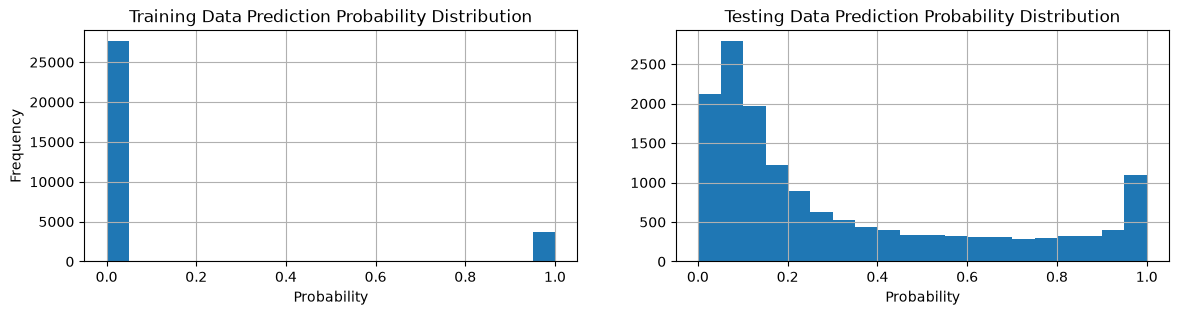

In [21]:
_, ax = plt.subplots(ncols=2, figsize = (14,3))

final_probability = pd.Series(best_lgbm.predict_proba(engineered_test.drop(columns=['index', 'txId']))[:,1])
final_probability = final_probability.reset_index().rename(columns={0:'target'})
y_pred.hist(ax = ax[0], bins = 20)
ax[0].set(
    title = "Training Data Prediction Probability Distribution",
    xlabel = "Probability",
    ylabel = "Frequency"
)
final_probability['target'].hist(ax = ax[1], bins = 20)
ax[1].set(
    title = "Testing Data Prediction Probability Distribution",
    xlabel = "Probability",
)

Probability output are well separated, with the model being relatively confident in predicting either the positive or negative case.

### Output to CSV

In [22]:
os.makedirs("./best_results/", exist_ok=True)
final_probability.to_csv('./best_results/final_preds.csv', index=False)

## Second-Best Submission Model

The second best submission model hyperparameters were fitted using the following parameters:

| `num_leaves` | `max_depth` | `learning_rate` | `n_estimators` | `subsample` | `colsample_bytree` | `reg_alpha` | `reg_lambda` | 
| ---------- | --------- | ------------- | ------------ | --------- | ---------------- | --------- | ---------- | 
| 40         | 4        | 0.31082        | 1,950        | 0.97882    | 0.96319          | 0.24638   | 4.86964    | 

It was original part of another `Optuna` study. However, the experiment files were lost, but the (approximate) parameters recorded.

In [23]:
second_params = {
    'num_leaves': 40,
    'max_depth': 4,
    'learning_rate': 0.31082,
    'n_estimators': 1950,
    'subsample': 0.97882,
    'colsample_bytree': 0.96319,
    'reg_alpha': 0.24638,
    'reg_lambda': 4.86964
}

second_lgbm = LGBMClassifier(
    **second_params,
    objective="binary",
    random_state=42,
    verbose = -1,
    is_unbalanced=True,
    subsample_freq=1,
)
second_lgbm.fit(X, y)

,num_leaves,40
,max_depth,4
,learning_rate,0.31082
,n_estimators,1950
,objective,'binary'
,subsample,0.97882
,subsample_freq,1
,colsample_bytree,0.96319
,reg_alpha,0.24638
,reg_lambda,4.86964
,random_state,42


### Accuracy Metrics

In [24]:
kfold = StratifiedKFold()
metrics = []
for idx, (train_index, val_index) in enumerate(kfold.split(X, y)):
    X_train, y_train = X.iloc[train_index], y.iloc[train_index]    
    X_test, y_test = X.iloc[val_index], y.iloc[val_index]
    second_lgbm.fit(
        X_train, y_train,
        eval_X=X_test, eval_y=y_test,
        eval_metric="auc",
        callbacks=[lightgbm.early_stopping(100, verbose=False)],
    )
    fold_y_pred = second_lgbm.predict_proba(X_test)[:,1]
    print(f" FOLD {idx + 1} METRICS ".center(50, "="))
    print(f"Train Size = {X_train.shape[0]}; Validation Size = {X_test.shape[0]}")
    metric = pd.DataFrame({
        "roc_auc": [roc_auc_score(y_test, fold_y_pred)],
        "precision": [precision_score(y_test, fold_y_pred > 0.5)],
        "recall": [recall_score(y_test, fold_y_pred > 0.5)],
        "f1-score": [f1_score(y_test, fold_y_pred > 0.5)],
        "accuracy": [accuracy_score(y_test, fold_y_pred > 0.5)],
    }, index=[idx + 1])
    metrics.append(metric)
    print(f"Classification Report:\n{classification_report(y_test, fold_y_pred > 0.5)}\n")
metrics = pd.concat(metrics)
metrics

================= FOLD 1 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98      5519
         1.0       1.00      0.71      0.83       728

    accuracy                           0.97      6247
   macro avg       0.98      0.86      0.91      6247
weighted avg       0.97      0.97      0.96      6247


================= FOLD 2 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99      5518
         1.0       0.98      0.94      0.96       729

    accuracy                           0.99      6247
   macro avg       0.98      0.97      0.98      6247
weighted avg       0.99      0.99      0.99      6247


================= FOLD 3 METRICS =================
Train Size = 24988; Validation Size = 6247
Classification R

,roc_auc,precision,recall,f1-score,accuracy
1,0.961526,0.998073,0.711538,0.830794,0.966224
2,0.996485,0.977077,0.935528,0.955851,0.989915
3,0.984345,0.974832,0.796982,0.876981,0.973907
4,0.965847,0.728665,0.913580,0.810712,0.950216
5,0.997376,0.477347,0.997257,0.645648,0.872259


In [25]:
metrics.describe()

,roc_auc,precision,recall,f1-score,accuracy
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,0.981116,0.831199,0.870977,0.823997,0.950504
std,0.016793,0.226651,0.114918,0.114263,0.046018
min,0.961526,0.477347,0.711538,0.645648,0.872259
25%,0.965847,0.728665,0.796982,0.810712,0.950216
50%,0.984345,0.974832,0.913580,0.830794,0.966224
75%,0.996485,0.977077,0.935528,0.876981,0.973907
max,0.997376,0.998073,0.997257,0.955851,0.989915


### Prediction validation

[Text(0.5, 1.0, 'Testing Data Prediction Probability Distribution'),
 Text(0.5, 0, 'Probability')]

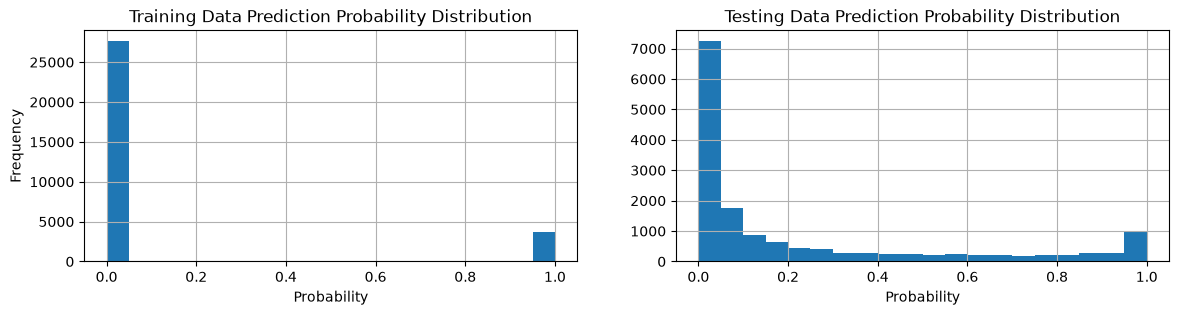

In [26]:
_, ax = plt.subplots(ncols=2, figsize = (14,3))

second_final_probability = pd.Series(second_lgbm.predict_proba(engineered_test.drop(columns=['index', 'txId']))[:,1])
second_final_probability = second_final_probability.reset_index().rename(columns={0:'target'})
y_pred.hist(ax = ax[0], bins = 20)
ax[0].set(
    title = "Training Data Prediction Probability Distribution",
    xlabel = "Probability",
    ylabel = "Frequency"
)
second_final_probability['target'].hist(ax = ax[1], bins = 20)
ax[1].set(
    title = "Testing Data Prediction Probability Distribution",
    xlabel = "Probability",
)

### Output to CSV

The original second best submission outputs the probability predictions as `final_preds.csv`. However, to avoid overwriting the best submission model output, the file name has been renamed to `final_preds(1).csv`

In [27]:
os.makedirs("./second_best_results/", exist_ok=True)
second_final_probability.to_csv('./second_best_results/final_preds.csv', index=False)